# Análise exploratória — Desempenho das escolas no ENEM (2009–2015)

**Alunos:** Gabryel Duarte Pessanha e Esther Corte Real
**Professor:** Alexandre Louzada
**Instituição:** Unilasalle — Bacharelado em Sistemas de Informação, 6º período
**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python)

Perguntas de pesquisa:
- **RQ1.** Como o desempenho das escolas públicas e privadas evoluiu entre 2009 e 2015 e qual é a diferença entre as redes?
- **RQ2.** Como o nível socioeconômico dos alunos (INSE) e a formação dos professores se relacionam com o desempenho?
- **RQ3.** Como o desempenho varia por região, estado e zona urbana/rural, e qual é a relação com o abandono escolar?

In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent))
pd.set_option("display.max_columns", 40); sns.set_theme(style="whitegrid")

## 1. Leitura do arquivo bruto
O arquivo do INEP usa codificação ISO-8859-1 e separador `;`. Primeiro lemos tudo como texto para verificar os dados antes de converter os tipos.

In [2]:
raw = extract()
print(raw.shape); raw.head(3)

INFO | Lendo arquivo bruto: MICRODADOS_ENEM_ESCOLA.csv.gz


INFO | Linhas brutas: 172,305 | Colunas: 27


(172305, 27)


,NU_ANO,CO_UF_ESCOLA,SG_UF_ESCOLA,CO_MUNICIPIO_ESCOLA,NO_MUNICIPIO_ESCOLA,CO_ESCOLA_EDUCACENSO,NO_ESCOLA_EDUCACENSO,TP_DEPENDENCIA_ADM_ESCOLA,TP_LOCALIZACAO_ESCOLA,NU_MATRICULAS,NU_PARTICIPANTES_NEC_ESP,NU_PARTICIPANTES,NU_TAXA_PARTICIPACAO,NU_MEDIA_CN,NU_MEDIA_CH,NU_MEDIA_LP,NU_MEDIA_MT,NU_MEDIA_RED,NU_MEDIA_OBJ,NU_MEDIA_TOT,INSE,PC_FORMACAO_DOCENTE,NU_TAXA_PERMANENCIA,NU_TAXA_APROVACAO,NU_TAXA_REPROVACAO,NU_TAXA_ABANDONO,PORTE_ESCOLA
0,2007,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,144,NaN,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69.03,NaN,NaN,NaN,91.90,8.10,0.00,Maior que 90 alunos
1,2006,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,184,NaN,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57.82,NaN,NaN,NaN,NaN,NaN,NaN,Maior que 90 alunos
2,2005,11,RO,1100205,Porto Velho,11000058,CENTRO DE ENSINO CLASSE A,4,1,220,NaN,145,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.83,NaN,NaN,NaN,86.50,12.40,1.10,Maior que 90 alunos


In [3]:
cob = raw.groupby("NU_ANO")[["NU_MEDIA_CN","NU_MEDIA_RED","PC_FORMACAO_DOCENTE","INSE","NU_TAXA_ABANDONO"]].apply(lambda g: g.notna().mean().round(2))
cob

,NU_MEDIA_CN,NU_MEDIA_RED,PC_FORMACAO_DOCENTE,INSE,NU_TAXA_ABANDONO
NU_ANO,,,,,
2005,0.0,0.00,0.0,0.0,0.99
2006,0.0,0.00,0.0,0.0,0.00
2007,0.0,0.00,0.0,0.0,0.98
2008,0.0,1.00,0.0,0.0,0.99
2009,1.0,0.99,0.0,0.0,0.99
2010,1.0,0.99,0.0,0.0,0.99
2011,1.0,1.00,0.0,0.0,0.99
2012,1.0,1.00,0.0,0.0,1.00
2013,1.0,1.00,1.0,0.0,1.00


Os anos 2005–2008 não têm médias por área, então esses registros são removidos. `INSE` e `PC_FORMACAO_DOCENTE` ficam como `NaN` nos anos em que não foram coletados.

## 2. Execução e validação do pipeline

In [4]:
df = transform(raw)
print(df.shape); df.dtypes

INFO | Registros com notas completas: 104,307 (removidos 67,998 sem notas — anos 2005-2008)


INFO | Inconsistências participantes>matriculas: 762 (mantidas e marcadas)


(104307, 27)


ano                        Int16
regiao                  category
uf                           str
co_municipio                 str
municipio                    str
co_escola                    str
escola                       str
dependencia             category
rede                         str
localizacao             category
porte                   category
matriculas                 int64
participantes              int64
taxa_participacao        float64
media_cn                 float64
media_ch                 float64
media_lp                 float64
media_mt                 float64
media_red                float64
media_geral              float64
inse                    category
inse_num                 Float64
pct_formacao_docente     float64
taxa_aprovacao           float64
taxa_reprovacao          float64
taxa_abandono            float64
flag_inconsistencia         bool
dtype: object

In [5]:
assert df[COLUNAS_NOTA].notna().all().all(), "há notas faltantes"
assert df.media_geral.between(0, 1000).all()
assert set(df.ano.unique()) == set(range(2009, 2016))
print("Inconsistências marcadas (participantes > matrículas):", df.flag_inconsistencia.sum())
df.describe().T.round(1)

Inconsistências marcadas (participantes > matrículas): 762


,count,mean,std,min,25%,50%,75%,max
ano,104307.0,2011.899058,2.111793,2009.0,2010.0,2012.0,2014.0,2015.0
matriculas,104307.0,95.037591,93.43398,0.0,32.0,64.0,124.0,1374.0
participantes,104307.0,56.335308,58.191321,10.0,20.0,36.0,70.0,992.0
taxa_participacao,104307.0,64.553864,23.151379,2.0,51.43,66.01,83.78,100.0
media_cn,104307.0,491.026026,51.808168,324.85,453.73,478.12,521.34,755.16
media_ch,104307.0,531.868559,55.273312,357.87,492.52,527.93,568.065,758.04
media_lp,104307.0,510.089447,48.05136,319.26,475.75,504.98,543.055,712.35
media_mt,104307.0,513.131223,73.13929,359.74,458.64,494.46,554.86,873.65
media_red,104307.0,557.053463,79.426922,141.88,505.095,558.33,608.82,930.0
media_geral,104307.0,520.633754,55.628951,313.67,480.38,509.1,556.22,763.66


In [6]:
df.groupby(["ano","dependencia"], observed=True).size().unstack()

dependencia,Estadual,Federal,Municipal,Privada
ano,,,,
2009,12955,170,232,4580
2010,13862,184,201,5169
2011,4968,199,111,4799
2012,5920,144,97,5361
2013,7679,283,109,6046
2014,8990,326,109,6215
2015,8836,328,109,6325


## 3. Distribuições

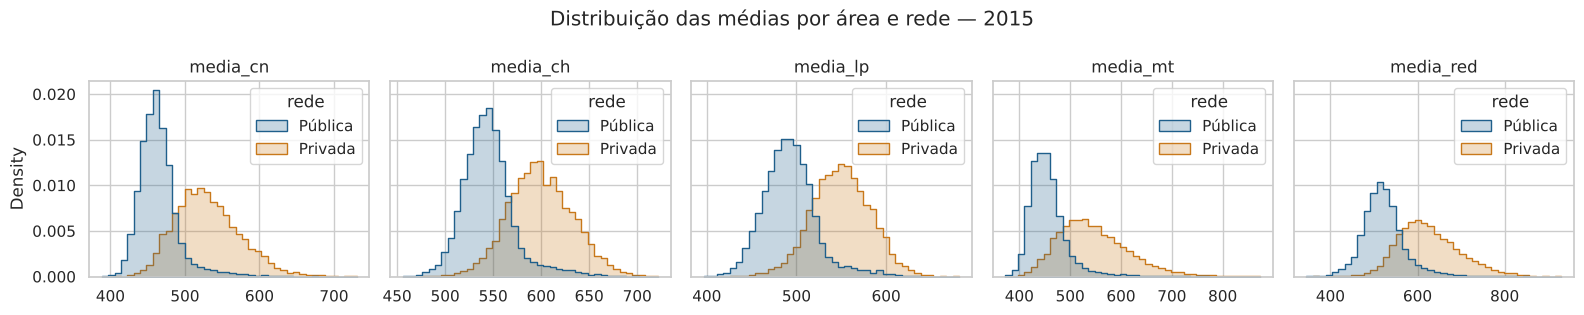

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for ax, c in zip(axes, COLUNAS_NOTA):
    sns.histplot(df[df.ano==2015], x=c, hue="rede", bins=40, ax=ax, element="step", stat="density", common_norm=False, palette={"Pública":"#1F5F8B","Privada":"#C8781A"})
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Distribuição das médias por área e rede — 2015"); plt.tight_layout()

Redação é a área com maior dispersão e Matemática a de maior diferença entre redes. Abaixo, a distribuição da média geral por dependência administrativa.

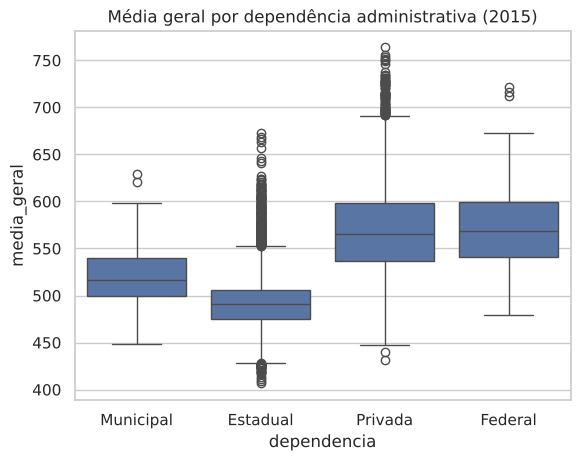

In [8]:
sns.boxplot(data=df[df.ano==2015], x="dependencia", y="media_geral", order=["Municipal","Estadual","Privada","Federal"])
plt.title("Média geral por dependência administrativa (2015)");

## 4. RQ1 — Evolução por rede

In [9]:
ev = media_por(df, ["ano","rede"]).pivot(index="ano", columns="rede", values="media_geral")
ev["gap"] = ev.Privada - ev.Pública
ev.round(1)

rede,Privada,Pública,gap
ano,,,
2009,595.4,497.6,97.8
2010,601.1,508.5,92.6
2011,584.2,495.2,89.0
2012,581.4,489.4,92.0
2013,579.7,490.5,89.3
2014,581.7,490.6,91.1
2015,586.4,499.9,86.5


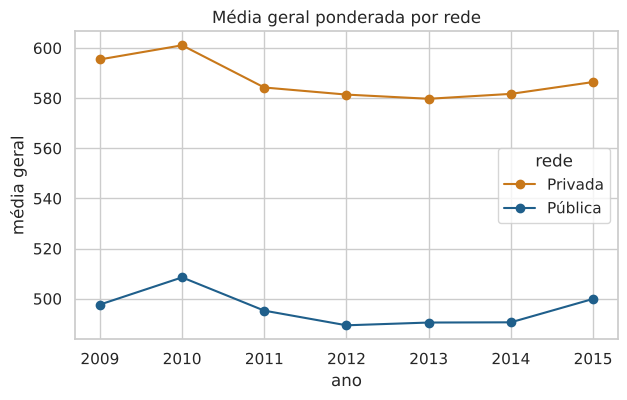

In [10]:
ev[["Privada","Pública"]].plot(marker="o", color=["#C8781A","#1F5F8B"], figsize=(7,4), title="Média geral ponderada por rede"); plt.ylabel("média geral");

In [11]:
d15 = df[df.ano==2015]
med_priv = d15[d15.rede=="Privada"].media_geral.median()
print(f"Mediana privada 2015: {med_priv:.1f}")
print("Escolas federais acima dessa mediana:", f"{(d15[d15.dependencia=='Federal'].media_geral > med_priv).mean():.1%}")
print("Escolas públicas (todas) acima dessa mediana:", f"{(d15[d15.rede=='Pública'].media_geral > med_priv).mean():.1%}")

Mediana privada 2015: 565.0
Escolas federais acima dessa mediana: 55.2%
Escolas públicas (todas) acima dessa mediana: 3.8%


## 5. RQ2 — Nível socioeconômico e formação docente

In [12]:
i15 = d15[d15.inse.notna()]
tab = i15.pivot_table(index="inse", columns="rede", values="media_geral", aggfunc=["mean","count"], observed=True).round(1)
tab

mean           count        
rede    Privada Pública Privada Pública
inse                                   
Grupo 1   504.1   466.8      27     980
Grupo 2   506.7   480.0      80    1310
Grupo 3   527.5   491.6     830    3915
Grupo 4   548.7   509.4    1284    2527
Grupo 5   572.4   545.8    2734     524
Grupo 6   617.2   640.5    1369      17

In [13]:
print("Spearman INSE x média geral (todas):", i15[["inse_num","media_geral"]].corr("spearman").iloc[0,1].round(3))
for r in ["Pública","Privada"]:
    s = i15[i15.rede==r]
    print(f"  {r}: {s[['inse_num','media_geral']].corr('spearman').iloc[0,1]:.3f}")

Spearman INSE x média geral (todas): 0.777
  Pública: 0.581
  Privada: 0.637


In [14]:
base = df[df.pct_formacao_docente.notna()]
print("Spearman formação docente x média geral (todas):", base[["pct_formacao_docente","media_geral"]].corr("spearman").iloc[0,1].round(3))
for r in ["Pública","Privada"]:
    s = base[base.rede==r]
    print(f"  {r}: {s[['pct_formacao_docente','media_geral']].corr('spearman').iloc[0,1]:.3f}")

Spearman formação docente x média geral (todas): 0.252
  Pública: 0.357
  Privada: 0.344


A correlação da formação docente com a nota é maior dentro de cada rede do que no conjunto. As duas redes têm formação docente parecida (mediana de 62%), mas notas muito diferentes, o que reduz a correlação quando os dados são juntados.

rede
Privada    62.2
Pública    61.6
Name: pct_formacao_docente, dtype: float64


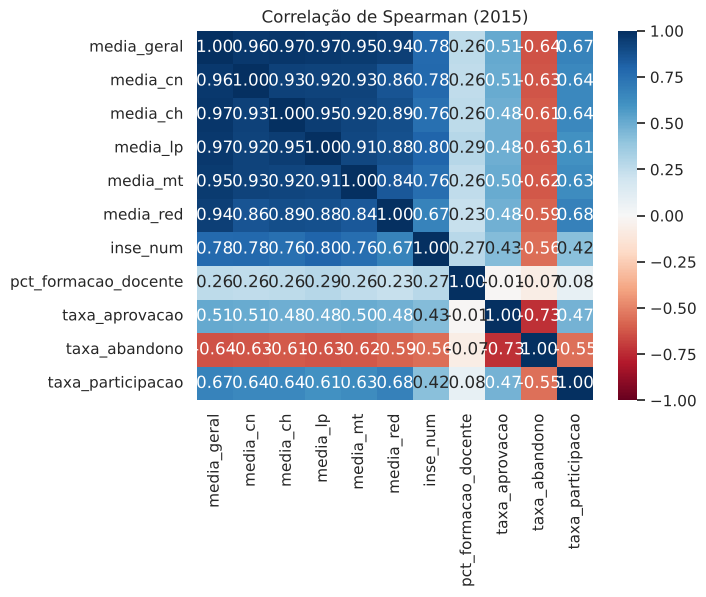

In [15]:
print(base.groupby("rede").pct_formacao_docente.median())
sns.heatmap(correlacoes(i15), annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1); plt.title("Correlação de Spearman (2015)");

## 6. RQ3 — Território e abandono

In [16]:
reg = media_por(d15, ["regiao","rede"]).pivot(index="regiao", columns="rede", values="media_geral").round(1)
reg["gap"] = reg.Privada - reg.Pública; reg

rede,Privada,Pública,gap
regiao,,,
Centro-Oeste,587.1,495.9,91.2
Nordeste,575.8,483.8,92.0
Norte,566.4,485.4,81.0
Sudeste,594.8,513.5,81.3
Sul,585.0,511.2,73.8


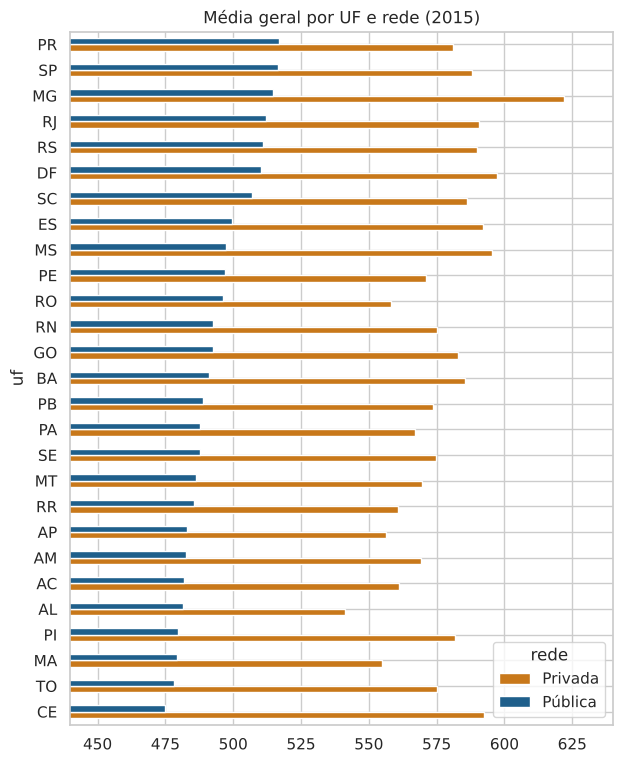

In [17]:
uf = media_por(d15, ["uf","rede"]).pivot(index="uf", columns="rede", values="media_geral").round(1).sort_values("Pública")
uf.plot.barh(figsize=(7,9), color=["#C8781A","#1F5F8B"], title="Média geral por UF e rede (2015)"); plt.xlim(440, 640);

In [18]:
pub = d15[d15.rede=="Pública"]
media_por(pub, ["regiao","localizacao"]).pivot(index="regiao", columns="localizacao", values="media_geral").round(1)

localizacao,Rural,Urbana
regiao,,
Centro-Oeste,497.9,495.9
Nordeste,481.5,483.9
Norte,479.9,485.6
Sudeste,519.1,513.4
Sul,506.1,511.4


In [19]:
p = pub.dropna(subset=["taxa_abandono"])
print("Spearman abandono x média (públicas 2015):", p[["taxa_abandono","media_geral"]].corr("spearman").iloc[0,1].round(3))
p.groupby(pd.qcut(p.taxa_abandono, 10, duplicates="drop"), observed=True).media_geral.median().round(1)

Spearman abandono x média (públicas 2015): -0.338


taxa_abandono
(-0.001, 0.5]    504.3
(0.5, 1.7]       500.8
(1.7, 3.1]       495.5
(3.1, 4.5]       492.8
(4.5, 6.3]       491.6
(6.3, 8.2]       488.0
(8.2, 10.76]     485.9
(10.76, 14.5]    482.1
(14.5, 85.7]     479.4
Name: media_geral, dtype: float64

## 7. Síntese da exploração
- A diferença entre redes é estável (86–98 pontos) e não se fechou no período.
- O INSE é o indicador mais fortemente associado à nota (ρ ≈ 0,78); escolas públicas de INSE alto alcançam as privadas.
- A formação docente tem associação positiva moderada dentro de cada rede (ρ ≈ 0,35).
- As diferenças regionais existem, mas são menores do que a diferença entre redes; zona urbana/rural pouco importa nas públicas.
- Abandono escolar correlaciona-se negativamente com a nota (ρ ≈ −0,34).

As figuras finais são geradas por `src/figuras.py` e incorporadas em `docs/index.html`.